In [27]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from estimator_functions import *

Actual A:
 [[1.005     0.0057735]
 [0.        0.995    ]]
Estimated A (last):
 [[ 9.89066284e-01 -1.62940343e-02]
 [-5.36853422e-05  8.59851647e-01]]
True unstable eigenvalue: 1.005
Tracked unstable eigenvalue: 0.9891706118504583
True left unstable eigenvector: [0.8660254 0.5      ]
Tracked left unstable eigenvector: [-0.99291524  0.11882478]
True noise strength (expected): 0.020000000000000004
Tracked noise strength (last): 775.8185331231612


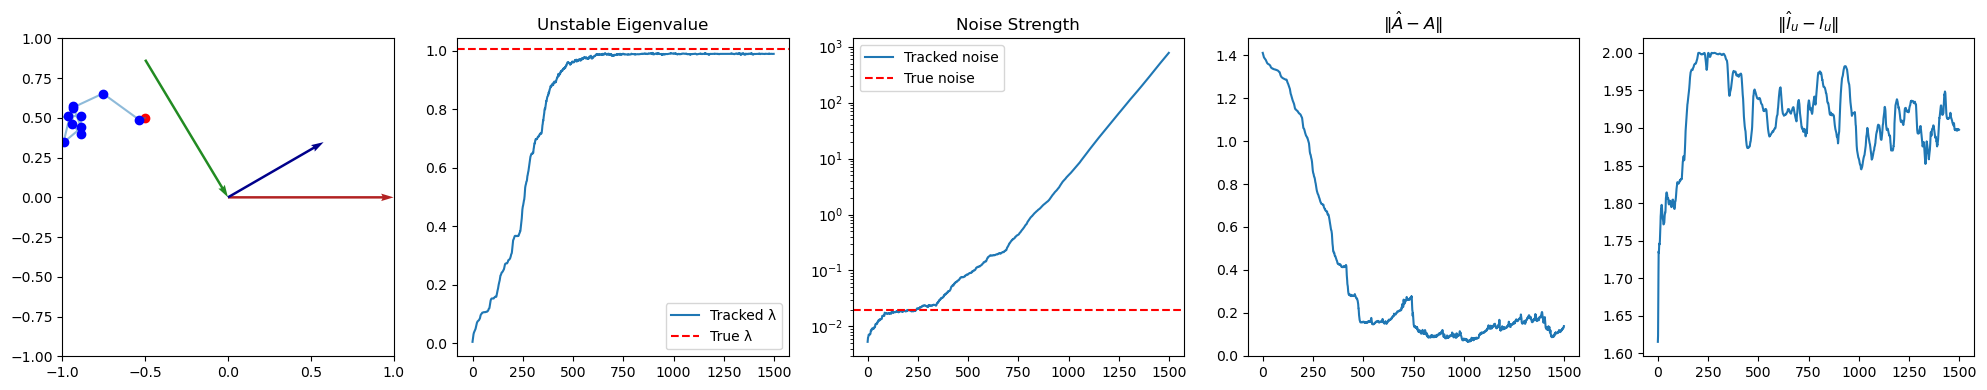

In [5]:
#def test_tracker():
np.random.seed(0)
dim = 2
T = 1500

# Ground-truth dynamics
theta = np.pi / 3
A_true =  .01 * np.array([
    [.5, 1/np.tan(theta)],
    [0.0, -0.5]
]) + np.eye(dim) 
eigenvalues, Q_mat = np.linalg.eig(A_true)
Lambda = np.diag(eigenvalues)
b_true =  np.array([0.1, -0.1]) * 0
noise_std = 0.1

# Generate trajectory
np.random.seed(2)
X = np.zeros((T, dim))
X[0] = np.array([-.5, .5]) #np.random.randn(dim)
for t in range(1, T):
    X[t] = A_true @ X[t-1] + b_true + noise_std * np.random.randn(dim)

# Initialize tracker
tracker = OnlineCovarianceTracker(dim, store_history=True)

# Run tracker
for t in range(1, T):
    tracker.step(X[t-1], X[t])

# Compare A_true to estimated A_t
A_est = tracker.A_history[-1]
print("Actual A:\n", A_true)
print("Estimated A (last):\n", A_est)

# Compare unstable eigenvectors and eigenvalues
eigvals, eigvecs = np.linalg.eig(A_true.T)  # left eigenvectors of A are right eigenvectors of A^T
idx_unstable = np.argmax(eigvals)
lambda_true = eigvals[idx_unstable].real
l_true = eigvecs[:, idx_unstable].real
l_true /= np.linalg.norm(l_true)

print("True unstable eigenvalue:", lambda_true)
print("Tracked unstable eigenvalue:", tracker.lambda_t)

print("True left unstable eigenvector:", l_true)
print("Tracked left unstable eigenvector:", tracker.l_unstable)

# Compare noise strength
true_noise_strength = noise_std**2 * dim  # expected squared norm
print("True noise strength (expected):", true_noise_strength)
print("Tracked noise strength (last):", tracker.noise_strength)

tracker.b_history = np.array(tracker.b_history)
# --- Plot comparisons ---
plt.figure(figsize=(20, 4))

plt.subplot(1, 5, 1)
plt.plot(X[0,0], X[0,1], 'ro')
plt.plot(X[:,0], X[:,1], alpha=0.5)
plt.plot(tracker.b_history[:,0], tracker.b_history[:,1], 'bo')
plt.quiver(b_true[0], b_true[1], Q_mat[0,0], Q_mat[1,0], angles='xy', scale_units='xy', scale=1, color='firebrick', label='Unstable Direction')
plt.quiver(Q_mat[0,1], Q_mat[1,1], -Q_mat[0,1], -Q_mat[1,1],
           angles='xy', scale_units='xy', scale=1,
           color='forestgreen', label='Stable Direction (arrow flipped)')
plt.quiver(b_true[0], b_true[1], l_true[0], l_true[1], color='darkblue', scale=3, label="True l_u")
plt.quiver(tracker.b_history[-1,0], tracker.b_history[-1,1], tracker.l_unstable[0], tracker.l_unstable[1], color='lightblue', scale=3, label="Tracked l_u")
plt.xlim([-1,1])
plt.ylim([-1,1])


# Eigenvalue history
plt.subplot(1, 5, 2)
plt.plot(tracker.lambda_history, label="Tracked λ")
plt.axhline(lambda_true, color='r', linestyle='--', label="True λ")
plt.legend(); plt.title("Unstable Eigenvalue")

# Noise strength history
plt.subplot(1, 5, 3)
plt.plot(tracker.noise_history, label="Tracked noise")
plt.yscale("log")
plt.axhline(true_noise_strength, color='r', linestyle='--', label="True noise")
plt.legend(); plt.title("Noise Strength")

# A matrix error
plt.subplot(1, 5, 4)
errors = [np.linalg.norm(A - A_true) for A in tracker.A_history]
plt.plot(errors)
plt.title("$\|\hat{A} - A\|$")

# left eigenvector error
plt.subplot(1,5,5)
errors = [np.linalg.norm(l - l_true) for l in tracker.lu_history]
plt.plot(errors)
plt.title("$\|\hat{l}_u - l_u\|$")

plt.tight_layout()
plt.show()


# Run test
#test_tracker()


# Testing linear model-based estimation

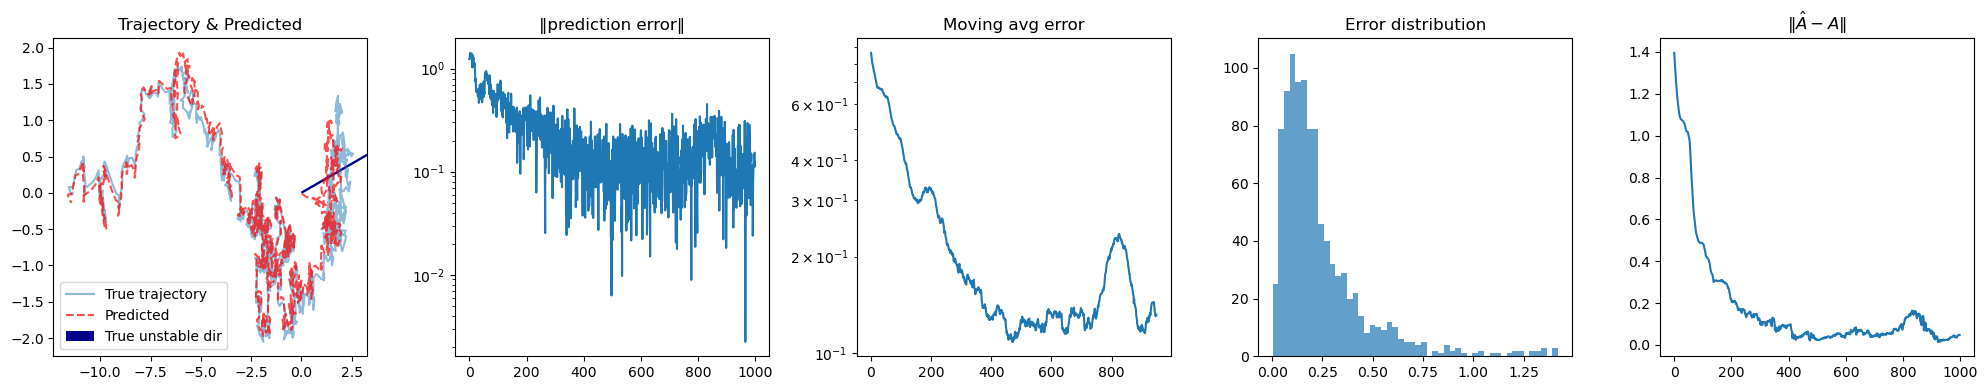

In [ ]:
#def test_covariance_tracker():
np.random.seed(0)
dim = 2
T = 1000

# Ground-truth dynamics (simple linear system)
#A_true = np.array([[0.9, 0.2], [-0.1, 0.8]])
b_true = np.array([0.0, 0.0])
noise_std = 0.1


# Generate trajectory
X = np.zeros((T, dim))
X[0] = np.array([1.0, -0.5])
for t in range(1, T):
    X[t] = A_true @ X[t-1] + b_true + noise_std * np.random.randn(dim)


# Initialize tracker
tracker = ExponentialCovarianceTracker(dim, gamma=0.98, store_history=True)

# Run tracker and measure prediction error
errors = []
preds = []
for t in range(1, T):
    tracker.step(X[t], X[t-1])
    x_pred = tracker.predict(X[t-1])
    preds.append(x_pred.ravel())
    e_t = X[t].reshape(-1,1) - x_pred
    err = np.linalg.norm(e_t)
    errors.append(err)
    # if tracker.store_history:
    #     tracker.pred_error_history.append(err)
    #     tracker.pred_history.append(x_pred.ravel())

preds = np.array(preds)

# Plot comparisons 
plt.figure(figsize=(20,4))

# 1. Phase portrait with predictions vs true
plt.subplot(1,5,1)
plt.plot(X[:,0], X[:,1], alpha=0.5, label="True trajectory")
plt.plot(preds[:,0], preds[:,1], 'r--', alpha=0.7, label="Predicted")
plt.quiver(0, 0, l_true[0], l_true[1], color='darkblue', scale=3, label="True unstable dir")
plt.legend(); plt.title("Trajectory & Predicted")


# 2. Prediction error norm
plt.subplot(1,5,2)
plt.plot(tracker.pred_error_history)
plt.yscale("log")
plt.title("‖prediction error‖")


# 3. Moving average error
plt.subplot(1,5,3)
window = 50
mov_avg = np.convolve(tracker.pred_error_history, np.ones(window)/window, mode='valid')
plt.plot(mov_avg)
plt.yscale("log")
plt.title("Moving avg error")

# 4. Error histogram
plt.subplot(1,5,4)
plt.hist(tracker.pred_error_history, bins=50, alpha=0.7)
plt.title("Error distribution")

plt.subplot(1, 5, 5)
errors = [np.linalg.norm(A - A_true) for A in tracker.A_history]
plt.plot(errors)
plt.title("$\|\hat{A} - A\|$")

plt.tight_layout()
plt.show()

#print("Final prediction error:", errors[-1])

# Run test
#test_covariance_tracker()

# Test on double well

In [11]:
# Double well system 
def potential(X, Y):
    return (X**2 - 1)**2 + 2*Y**2

def drift_func(t, x):
    dx0 = -1 * x[0] * (x[0]**2 - 1)
    dx1 = -4 * x[1]
    return np.array([dx0, dx1])

np.random.seed(0)
T = 500
dt = 0.01
dim = 2
X = np.zeros((T, dim))
X[0] = np.array([0.05, 0.05])  # start near saddle
noise_std = 0.01

for t in range(1, T):
    dx = drift_func(t, X[t-1])
    X[t] = X[t-1] + dx*dt + noise_std*np.random.randn(dim)

Linearized dynamics at saddle:
 [[ 1  0]
 [ 0 -4]]
Inferred linear map (last step):
 [[-47.20167028   0.35935443]
 [  0.45115419 -98.44786513]]


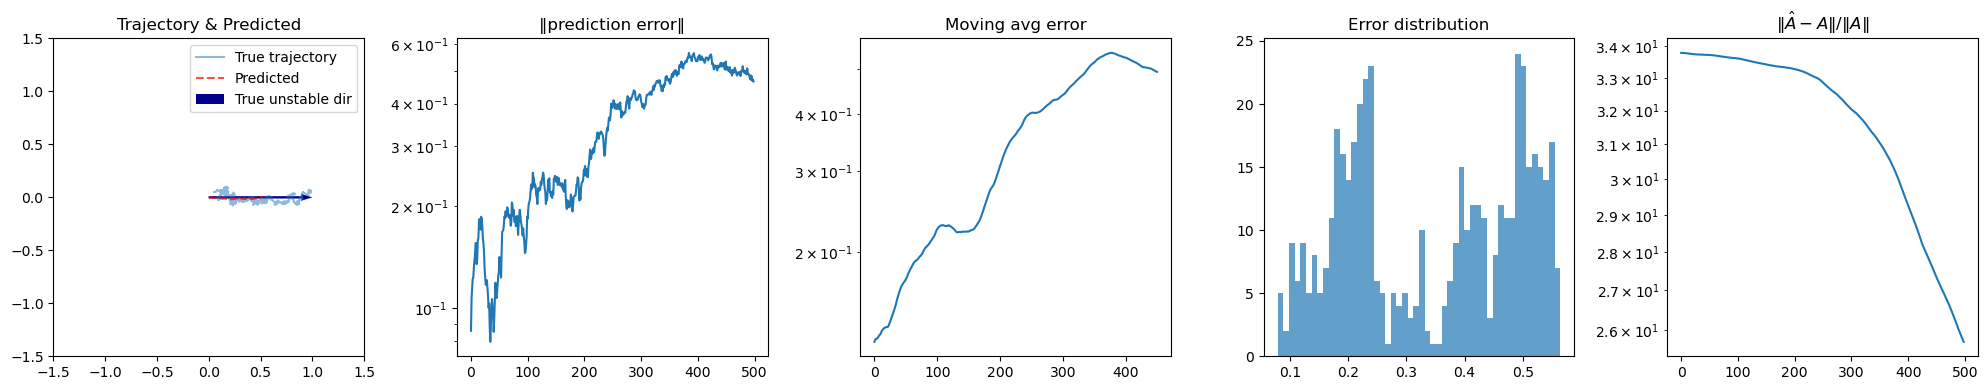

In [12]:
tracker = ExponentialCovarianceTracker(dim, gamma=0.995)
#tracker = OnlineCovarianceTracker(dim, store_history=True)
for t in range(1, T):
    tracker.step(X[t], X[t-1])

# --- Compare inferred A to linearization at saddle ---
A_linearized = np.array([[1, 0], [0, -4]])
#A_linearized = np.eye(2) + A_linearized * dt
A_stable =  np.array([[-2, 0], [0, -4]]) #* dt +np.eye(2) +
A_est = (tracker.A_history[-1] - np.eye(2)) / dt

print("Linearized dynamics at saddle:\n", A_linearized)
print("Inferred linear map (last step):\n", A_est)

# Plot comparisons 
plt.figure(figsize=(20,4))
tracker.pred_history = np.array(tracker.pred_history)
# 1. Phase portrait with predictions vs true
plt.subplot(1,5,1)
plt.plot(X[:,0], X[:,1], alpha=0.5, label="True trajectory")
plt.plot(tracker.pred_history[:,0], tracker.pred_history[:,1], 'r--', alpha=0.7, label="Predicted")
plt.quiver(0, 0, 1, 0, color='darkblue', scale=3, label="True unstable dir")
plt.legend(); plt.title("Trajectory & Predicted")
plt.xlim([-1.5,1.5])
plt.ylim([-1.5,1.5])


# 2. Prediction error norm
plt.subplot(1,5,2)
plt.plot(tracker.pred_error_history)
plt.yscale("log")
plt.title("‖prediction error‖")

# 3. Moving average error
plt.subplot(1,5,3)
window = 50
mov_avg = np.convolve(tracker.pred_error_history, np.ones(window)/window, mode='valid')
plt.plot(mov_avg)
plt.yscale("log")
plt.title("Moving avg error")

# 4. Error histogram
plt.subplot(1,5,4)
plt.hist(tracker.pred_error_history, bins=50, alpha=0.7)
plt.title("Error distribution")

plt.subplot(1, 5, 5)
# errors = [np.linalg.norm(A - A_true) for A in tracker.A_history]
rel_error = np.array([np.linalg.norm((A-np.eye(2))/dt - A_linearized, 'fro') for A in tracker.A_history]) / np.linalg.norm(A_linearized, 'fro')
plt.plot(rel_error)
# rel_error = np.array([np.linalg.norm((A-np.eye(2))/dt  - A_stable, 'fro') for A in tracker.A_history]) / np.linalg.norm(A_stable, 'fro')
# plt.plot(rel_error)
plt.yscale("log")
plt.title("$\|\hat{A} - A\| / \|A\|$")

plt.tight_layout()
plt.show()

In [46]:
class OnlineCovarianceTracker:
    def __init__(self, dim, eta_mean=0.05, eta_M=0.01, eta_w=0.01, eta_e=0.01, store_history=True):
        self.dim = dim
        self.eta_mean = eta_mean
        self.eta_M = eta_M
        self.eta_w = eta_w
        self.eta_e = eta_e

        self.b = np.zeros(dim)
        self.Mfp = np.zeros((dim, dim))
        self.Mpf = np.zeros((dim, dim))
        self.Wpp = np.eye(dim)
        self.p_mean = np.zeros(dim)
        self.f_mean = np.zeros(dim)

        # Eigen-tracking state
        self.l_unstable = np.random.randn(dim)
        self.l_unstable /= np.linalg.norm(self.l_unstable)
        self.l_stable = self.l_unstable.copy()
        self.lambda_t = np.random.randn(1)

        # Noise strength
        self.noise_strength = 0.0

        self.store_history = store_history
        if store_history:
            self.b_history = []
            self.dp_history = []
            self.df_history = []
            self.et_history = []
            self.y_history = []
            self.xstar_history = []
            self.A_history = []
            self.lu_history = []
            self.ls_history = []
            self.lambda_history = []
            self.noise_history = []

            # Add plotting histories like ExponentialCovarianceTracker
            self.pred_history = []
            self.pred_error_history = []

    def _update_left_eigenvectors(self):
        A_t = self.Mfp @ self.Wpp

        # Apply power iteration step
        v = self.l_unstable @ A_t
        norm_v = np.linalg.norm(v)
        if norm_v > 1e-12:
            self.l_unstable = v / norm_v

        # Eigenvalue estimate via Rayleigh quotient
        num = self.l_unstable @ (A_t @ self.l_unstable)
        den = self.l_unstable @ self.l_unstable
        self.lambda_t = float(num / den)

        # Stable eigenvector (scaled version)
        if abs(self.lambda_t) > 1e-12:
            self.l_stable = v / self.lambda_t

        if self.store_history:
            self.lu_history.append(self.l_unstable.copy())
            self.ls_history.append(self.l_stable.copy())
            self.lambda_history.append(self.lambda_t)

    def _update_noise_strength(self, et):
        new_val = float(np.dot(et, et))
        self.noise_strength = (1 - self.eta_e) * self.noise_strength + self.eta_e * new_val
        if self.store_history:
            self.noise_history.append(self.noise_strength)

    def predict(self, x_prev):
        """Predict next state using current Mfp and Wpp."""
        return (self.Mfp @ self.Wpp @ x_prev).ravel()

    def step(self, x_prev, x_t):
        self.Mfp, self.Mpf, self.p_mean, df, dp = hebbian_update_Mfp_Mpf(
            self.Mfp, self.Mpf, self.p_mean, x_prev, x_t,
            self.eta_mean, self.eta_M
        )

        self.Wpp, self.p_mean, dp, y_t = update_Wpp(
            self.Wpp, self.p_mean, x_t,
            self.eta_mean, self.eta_w
        )

        self.b, et = online_fixed_point_step(
            self.b, x_t, x_prev, self.Mfp, self.Mpf, self.Wpp
        )

        # Update eigen-tracking
        self._update_left_eigenvectors()

        # Update noise strength
        self._update_noise_strength(et)

        # --- Store histories for plotting ---
        if self.store_history:
            self.b_history.append(self.b.copy())
            self.dp_history.append(dp.copy())
            self.df_history.append(df.copy())
            self.et_history.append(et.copy())
            self.y_history.append(y_t.copy())

            # Effective system matrix
            try:
                A_tilde = self.Mfp @ self.Wpp
                self.A_history.append(A_tilde)
                x_star = -np.linalg.inv(A_tilde) @ self.b
            except np.linalg.LinAlgError:
                self.A_history.append(np.full((self.dim, self.dim), np.nan))
                x_star = np.full_like(self.b, np.nan)
            self.xstar_history.append(x_star)

            # Predictions & errors like ExponentialCovarianceTracker
            x_pred = self.predict(x_prev)
            e_pred = x_t - x_pred
            self.pred_history.append(x_pred.copy())
            self.pred_error_history.append(np.linalg.norm(e_pred))

        return self.b

    
    def reset_trajectory(self):
        """Reset any trajectory-dependent state (means, previous states, etc.)"""
        self.p_mean = np.zeros(self.dim)
        self.f_mean = np.zeros(self.dim)
        self.b = np.zeros(self.dim)


In [106]:
class OnlineCovarianceTracker:
    def __init__(self, dim, eta_mean=0.05, eta_M=0.01, eta_w=0.01, eta_e=0.01, store_history=True):
        self.dim = dim
        self.eta_mean = eta_mean
        self.eta_M = eta_M
        self.eta_w = eta_w
        self.eta_e = eta_e

        self.b = np.zeros(dim)
        self.Mfp = np.zeros((dim, dim))
        self.Mpf = np.zeros((dim, dim))
        self.Wpp = np.eye(dim)
        self.p_mean = np.zeros(dim)
        self.f_mean = np.zeros(dim)

        # Eigen-tracking state
        self.l_unstable = np.random.randn(dim)
        self.l_unstable /= np.linalg.norm(self.l_unstable)
        self.l_stable = self.l_unstable.copy()
        self.lambda_t = np.random.randn(1)

        # Noise strength
        self.noise_strength = 0.0

        self.store_history = store_history
        if store_history:
            self.b_history = []
            self.dp_history = []
            self.df_history = []
            self.et_history = []
            self.y_history = []
            self.xstar_history = []
            self.A_history = []
            self.lu_history = []
            self.ls_history = []
            self.lambda_history = []
            self.noise_history = []

            # Add plotting histories like ExponentialCovarianceTracker
            self.pred_history = []
            self.pred_error_history = []

    def _update_left_eigenvectors(self):
        A_t = self.Mfp @ self.Wpp

        # Apply power iteration step
        v = self.l_unstable @ A_t
        norm_v = np.linalg.norm(v)
        if norm_v > 1e-12:
            self.l_unstable = v / norm_v

        # Eigenvalue estimate via Rayleigh quotient
        num = self.l_unstable @ (A_t @ self.l_unstable)
        den = self.l_unstable @ self.l_unstable
        self.lambda_t = float(num / den)

        # Stable eigenvector (scaled version)
        if abs(self.lambda_t) > 1e-12:
            self.l_stable = v / self.lambda_t

        if self.store_history:
            self.lu_history.append(self.l_unstable.copy())
            self.ls_history.append(self.l_stable.copy())
            self.lambda_history.append(self.lambda_t)

    def _update_noise_strength(self, et):
        new_val = float(np.dot(et, et))
        self.noise_strength = (1 - self.eta_e) * self.noise_strength + self.eta_e * new_val
        if self.store_history:
            self.noise_history.append(self.noise_strength)

    def predict(self, x_prev):
        """Predict next state using current Mfp and Wpp."""
        return (self.Mfp @ self.Wpp @ x_prev).ravel()

    def step(self, x_prev, x_t):
        self.Mfp, self.Mpf, self.p_mean, df, dp = hebbian_update_Mfp_Mpf(
            self.Mfp, self.Mpf, self.p_mean, x_prev, x_t,
            self.eta_mean, self.eta_M
        )

        self.Wpp, self.p_mean, dp, y_t = update_Wpp(
            self.Wpp, self.p_mean, x_t,
            self.eta_mean, self.eta_w
        )

        self.b, et = online_fixed_point_step(
            self.b, x_t, x_prev, self.Mfp, self.Mpf, self.Wpp
        )

        # Update eigen-tracking
        self._update_left_eigenvectors()

        # Update noise strength
        self._update_noise_strength(et)

        # --- Store histories for plotting ---
        if self.store_history:
            self.b_history.append(self.b.copy())
            self.dp_history.append(dp.copy())
            self.df_history.append(df.copy())
            self.et_history.append(et.copy())
            self.y_history.append(y_t.copy())

            # Effective system matrix
            try:
                A_tilde = self.Mfp @ self.Wpp
                self.A_history.append(A_tilde)
                x_star = -np.linalg.inv(A_tilde) @ self.b
            except np.linalg.LinAlgError:
                self.A_history.append(np.full((self.dim, self.dim), np.nan))
                x_star = np.full_like(self.b, np.nan)
            self.xstar_history.append(x_star)

            # Predictions & errors like ExponentialCovarianceTracker
            x_pred = self.predict(x_prev)
            e_pred = x_t - x_pred
            self.pred_history.append(x_pred.copy())
            self.pred_error_history.append(np.linalg.norm(e_pred))

        return self.b


In [117]:
# Parameters
T = 100       # steps per trajectory
dt = 0.01
dim = 2
noise_std = 0.1

# Multiple initial positions
np.random.seed(0)
initial_positions = [np.random.uniform(-.1, .1, size=(dim,)) for _ in range(50)]

# Initialize tracker
tracker = ExponentialCovarianceTracker(dim, gamma=0.995, store_history=True)
#tracker = OnlineCovarianceTracker(dim, store_history=True)

all_X_uncontrolled = []
np.random.seed(0)
for x0 in initial_positions:
    # Initialize trajectory
    X = np.zeros((T, dim))
    X[0] = x0

    # Simulate trajectory
    for t in range(1, T):
        dx = drift_func(t, X[t-1])
        X[t] = X[t-1] + dx*dt + noise_std*np.random.randn(dim)*np.sqrt(dt)

        # Step tracker
        tracker.step(X[t], X[t-1])

    #tracker.reset_trajectory()
    all_X_uncontrolled.append(X)

In [118]:
A_smooth = np.mean(tracker.A_history[-500:], axis=0)  # average last 500 steps
A_est = (A_smooth - np.eye(tracker.dim)) / dt
Lambda_est, Q_mat_est = np.linalg.eig(A_est)
A_est

array([[ 0.88141585, -2.22149212],
       [ 0.41264198, -5.03993787]])

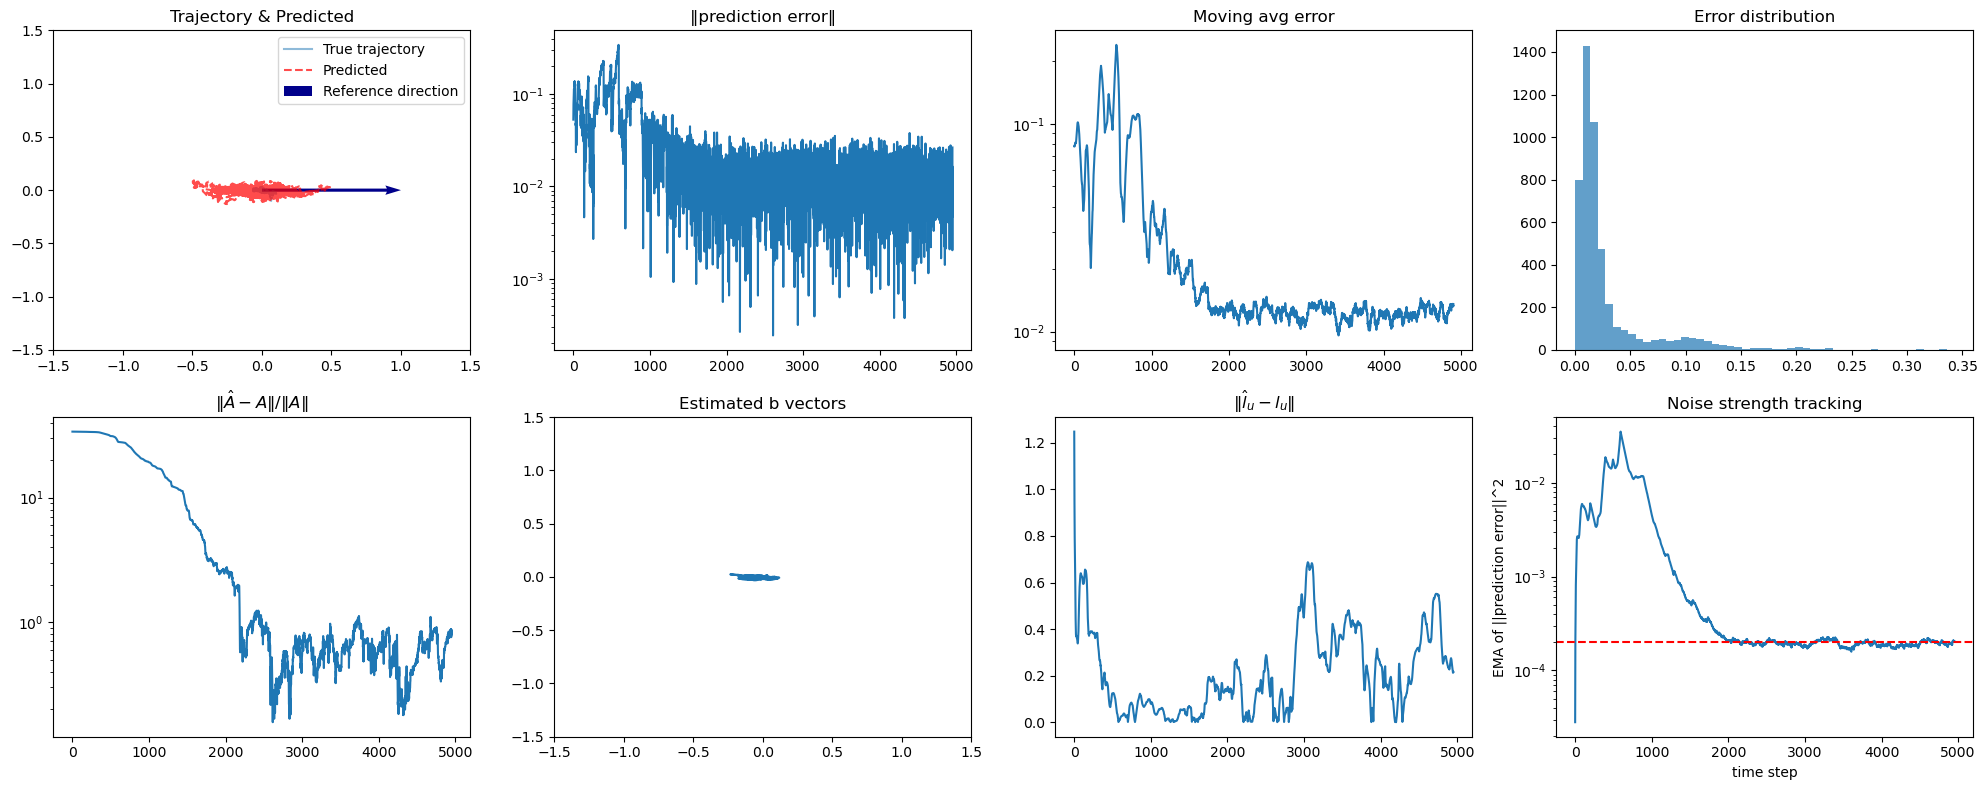

In [123]:
tracker.pred_history = np.array(tracker.pred_history)
tracker.b_history = np.array(tracker.b_history)
tracker.lu_history = np.array(tracker.lu_history)
tracker.noise_history = np.array(tracker.noise_history)

l_true = -np.array([1, 0])

plt.figure(figsize=(20,8))

# 1. Phase portrait with predictions vs true
plt.subplot(2,4,1)
plt.plot(X[:,0], X[:,1], alpha=0.5, label="True trajectory")
plt.plot(tracker.pred_history[:,0], tracker.pred_history[:,1], 'r--', alpha=0.7, label="Predicted")
plt.quiver(0, 0, 1, 0, color='darkblue', scale=3, label="Reference direction")
plt.legend(); plt.title("Trajectory & Predicted")
plt.xlim([-1.5,1.5])
plt.ylim([-1.5,1.5])

# 2. Prediction error norm
plt.subplot(2,4,2)
plt.plot(tracker.pred_error_history)
plt.yscale("log")
plt.title("‖prediction error‖")

# 3. Moving average error
plt.subplot(2,4,3)
window = 50
mov_avg = np.convolve(tracker.pred_error_history, np.ones(window)/window, mode='valid')
plt.plot(mov_avg)
plt.yscale("log")
plt.title("Moving avg error")

# 4. Error histogram
plt.subplot(2,4,4)
plt.hist(tracker.pred_error_history, bins=50, alpha=0.7)
plt.title("Error distribution")

# 5. Relative error in continuous-time linearization
plt.subplot(2,4,5)
rel_error = np.array([
    np.linalg.norm((A - np.eye(2))/dt - A_linearized, 'fro') / np.linalg.norm(A_linearized, 'fro')
    for A in tracker.A_history
])
plt.plot(rel_error)
plt.yscale("log")
plt.title("$\|\hat{A} - A\| / \|A\|$")

#
tracker.b_history = np.array(tracker.b_history)
plt.subplot(2,4,6)
plt.plot(tracker.b_history[:,0], tracker.b_history[:,1])
plt.xlim([-1.5, 1.5])
plt.ylim([-1.5, 1.5])
plt.title("Estimated b vectors")


plt.subplot(2,4,7)
errors = [np.min([np.linalg.norm(l - l_true),np.linalg.norm(l + l_true)]) for l in tracker.lu_history]
plt.plot(errors)
plt.title("$\|\hat{l}_u - l_u\|$") #min of both norms

plt.subplot(2,4,8)
plt.plot(tracker.noise_history)
true_noise_strength = dim * noise_std**2  * dt
plt.axhline(true_noise_strength, color='r', linestyle='--', label="True noise strength")
plt.yscale("log")
plt.title("Noise strength tracking")
plt.xlabel("time step")
plt.ylabel("EMA of ||prediction error||^2")

plt.tight_layout()
plt.show()

In [120]:
A_est = (tracker.A_history[-1] - np.eye(2)) / dt

print("Linearized dynamics at saddle:\n", A_linearized)
print("Inferred linear map (last step):\n", A_est)
Lambda_est, Q_mat_est = np.linalg.eig(A_est)
print("Inferred eigenvalues:", Lambda_est)

Linearized dynamics at saddle:
 [[ 1  0]
 [ 0 -4]]
Inferred linear map (last step):
 [[ 0.87868535 -1.53284732]
 [ 0.28509968 -6.88851917]]
Inferred eigenvalues: [ 0.82200773 -6.83184156]


In [115]:
X_prev = []
X_next = []
for X in all_X_uncontrolled:
    X_prev.append(X[:-1])
    X_next.append(X[1:])

X_prev = np.vstack(X_prev)  # shape (N_total_steps, dim)
X_next = np.vstack(X_next)

# Solve for continuous-time Jacobian A such that X_next - X_prev ≈ A @ X_prev * dt
A_est, _, _, _ = np.linalg.lstsq(X_prev * dt, (X_next - X_prev), rcond=None)

Lambda_est, Q_mat_est = np.linalg.eig(A_est)
print("Stable inferred A:\n", A_est)
print("Eigenvalues:", Lambda_est)

Stable inferred A:
 [[ 0.97014036  0.02574071]
 [-1.1664664  -4.16929159]]
Eigenvalues: [ 0.96429149 -4.16344272]


In [92]:
from scipy.integrate import quad
from scipy.special import erf
from scipy.special import logsumexp


## Control

In [93]:
def relu_control_1d(u, lambda_u):
    """1D ReLU control along unstable coordinate."""
    signal = 2 * lambda_u * u
    return -np.maximum(signal, 0.0)

def relu_control(tracker, x, r=1.0, x_fp=None):
    """
    Compute control along the unstable mode, applied only inside neighborhood of fixed point:
        u = - ReLU(2 * lambda_u * (l_u · (x - x_fp)) ) * l_u

    Parameters
    ----------
    tracker : ExponentialCovarianceTracker
        The online estimator holding l_unstable and lambda_t.
    x : np.ndarray
        Current state.
    r : float
        Radius of neighborhood around fixed point where control is active.
    x_fp : np.ndarray or None
        Fixed point estimate. If None, assume fixed point at origin.
    """
    if x_fp is None:
        x_fp = np.zeros_like(x)

    # Distance to fixed point
    dist = np.linalg.norm(x - x_fp)
    if dist > r:
        return np.zeros_like(x)   # no control outside neighborhood

    l_u = tracker.l_unstable
    lambda_u = tracker.lambda_t

    # Projection along unstable mode
    proj = np.dot(l_u, x - x_fp)

    # Mode activation
    signal = 2 * lambda_u * proj 

    # Negative ReLU  
    control = -np.maximum(signal, 0.0)* l_u

    return control

def committor_1d(u, a, r):
    """
    Compute committor q(u) for 1D OU unstable coordinate.
    """
    num, _ = quad(lambda y: np.exp(-0.5 * r * y**2), -a, u)
    den, _ = quad(lambda y: np.exp(-0.5 * r * y**2), -a, a)
    return num / den

def committor_control(tracker, x, r=1.0, x_fp=None, a=1.0, D=1.0):
    """
    Optimal committor control for stochastic dynamics near saddle.

    Parameters
    ----------
    tracker : ExponentialCovarianceTracker
        Holds l_unstable (unit vector) and lambda_t (unstable eigenvalue).
    x : np.ndarray
        Current state.
    r : float
        Radius of neighborhood around fixed point where control is active.
    x_fp : np.ndarray or None
        Fixed point estimate. If None, assume origin.
    a : float
        Absorbing boundary threshold in unstable coordinate.
    D : float
        Diffusion coefficient (inverse temperature).
    """
    if x_fp is None:
        x_fp = np.zeros_like(x)

    # Distance to fixed point
    dist = np.linalg.norm(x - x_fp)
    if dist > r:
        return np.zeros_like(x)

    l_u = tracker.l_unstable
    lambda_u = tracker.lambda_t

    # Projection onto unstable coordinate
    u = np.dot(l_u, x - x_fp)

    # Parameter r = lambda_u / (2D)
    rho = lambda_u / (2*D)

    # Committor function and derivative ratio
    q_u = committor_1d(u, a, rho)
    # q'(u) = exp(-0.5*r*u^2) / ∫_{-a}^a exp(-0.5*r*y^2) dy
    den, _ = quad(lambda y: np.exp(-0.5 * rho * y**2), -a, a)
    q_prime = np.exp(-0.5 * rho * u**2) / den

    # Optimal committor control
    control_scalar = 2 * D * (q_prime / max(q_u, 1e-12))  # avoid div by zero
    control = control_scalar * l_u

    return control


def committor_control_stable(tracker, x, r=1.0, x_fp=None, a=1.0, D=1.0):
    if x_fp is None:
        x_fp = np.zeros_like(x)

    dist = np.linalg.norm(x - x_fp)
    if dist > r:
        return np.zeros_like(x)

    l_u = tracker.l_unstable
    lambda_u = tracker.lambda_t
    u = np.dot(l_u, x - x_fp)
    rho = lambda_u / (2*D)

    # Use a fine grid for integral
    y = np.linspace(-a, u, 200)
    log_integrand = -0.5 * rho * y**2
    log_q = logsumexp(log_integrand) - np.log(len(y)) - np.log(sum(np.exp(-0.5 * rho * np.linspace(-a, a, 500)**2)))
    log_q_prime = -0.5 * rho * u**2 - np.log(sum(np.exp(-0.5 * rho * np.linspace(-a, a, 500)**2)))

    control_scalar = 2 * D * np.exp(log_q_prime - log_q)
    control = control_scalar * l_u
    return control

import mpmath   #for high precision calculations
mpmath.mp.dps = 200  # decimal places
def high_precision_control(xs: np.ndarray, a: float, r: float, D: float, precision: int = 50) -> np.ndarray:
    """
    Compute high-precision control values using mpmath for integration and exponentiation.
    
    Parameters:
        xs : np.ndarray
            Points at which to evaluate the control.
        a : float
            Integration limit (-a to x).
        r : float
            Rate parameter in the exponential.
        D : float
            Scaling constant.
        precision : int
            Decimal precision for mpmath.

    Returns:
        np.ndarray of control values, dtype float64, filled with np.nan where integral is too small.
    """
    mpmath.mp.dps = precision
    a_mpf = mpmath.mpf(a)
    r_mpf = mpmath.mpf(r)
    D_mpf = mpmath.mpf(D)

    control_exact = np.zeros_like(xs, dtype=np.float64)

    for i, x in enumerate(xs):
        x_mpf = mpmath.mpf(x)

        # Define the integrand
        integrand = lambda y: mpmath.exp(-r_mpf * y**2)

        # High-precision definite integral
        try:
            integral_val = mpmath.quad(integrand, [-a_mpf, x_mpf])
        except Exception:
            integral_val = mpmath.mpf(0)

        numerator = 2 * D_mpf * mpmath.exp(-r_mpf * x_mpf**2)
        control_exact[i] = float(numerator / (integral_val + mpmath.mpf('1e-500')))
        # if mpmath.fabs(integral_val) > mpmath.mpf('1e-1000'):
        #     numerator = 2 * D_mpf * mpmath.exp(-r_mpf * x_mpf**2)
        #     control_exact[i] = float(numerator / integral_val)
        # else:
        #     control_exact[i] = np.nan

    return control_exact

In [94]:
print("hatlambda = {:.2f}".format(tracker.lambda_history[-1]))
D = tracker.noise_strength / dim
print("hatD = {:.4f}".format(D))

hatlambda = 1.11
hatD = 0.0002


In [77]:
# Vectorize
a = .5
D = tracker.noise_strength / dim
r = tracker.lambda_history[-1] / (2*D)

u_vals = np.linspace(-a, a, 500)

# Committor function using erf
sqrt_r2 = np.sqrt(r/2)
q_vals = (erf(sqrt_r2 * u_vals) - erf(-sqrt_r2 * a)) / (erf(sqrt_r2 * a) - erf(-sqrt_r2 * a))

# q'(u) using analytic derivative
q_prime = np.sqrt(2*r/np.pi) * np.exp(-0.5 * r * u_vals**2) / (erf(sqrt_r2 * a) - erf(-sqrt_r2 * a))

# Committor control u* = 2 D q'/q
u_star = 2 * D * q_prime / np.maximum(q_vals, 1e-12)  # avoid division by zero

u_star_hp = high_precision_control(u_vals, a=0.5, r=r, D=D, precision=25)

u_relu = -relu_control_1d(-u_vals, lambda_u=tracker.lambda_history[-1])

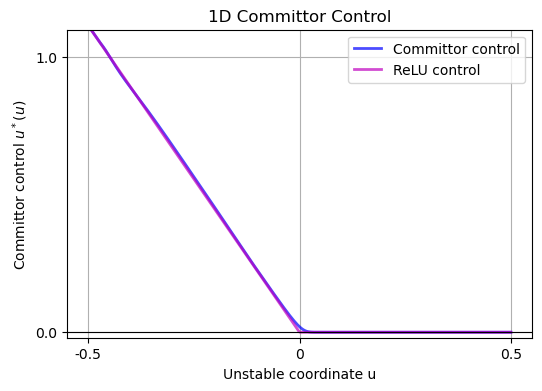

In [78]:
# Plot
plt.figure(figsize=(6,4))
plt.plot(u_vals, u_star_hp, 'b', lw=2, label='Committor control', alpha=0.7)
plt.plot(u_vals, u_relu, 'm', lw=2, label='ReLU control', alpha=0.7)
plt.axhline(0, color='k', lw=0.8)
#plt.axvline(-a, color='r', ls='--', label='Absorbing A')
#plt.axvline(a, color='g', ls='--', label='Absorbing B')
plt.xticks([-a, 0, a], [f'{-a:.1f}', '0', f'{a:.1f}'])
plt.yticks([0, 2*a], [f'{0:.1f}', f'{2*a:.1f}'])
plt.ylim([-0.02, 2*a + 0.1])
plt.xlabel("Unstable coordinate u")
plt.ylabel("Committor control $u^*(u)$")
plt.title("1D Committor Control")
plt.legend()
plt.grid(True)
plt.show()

In [133]:
def optimal_control(x, l_unstable, r, noise_std):
    dist = np.linalg.norm(x)
    if dist > r:
        return np.zeros_like(x)
    u_scalar = -np.dot(l_unstable, x)
    return -high_precision_control([u_scalar], a=0.5, r=1/(2*noise_std), D=noise_std, precision=25)[0] * l_unstable

def relu_control_func(x, tracker):
    return relu_control(tracker, x, r=0.5)

def committor_control_func(x, tracker, r, D):
    x_fp = np.zeros_like(x)
    dist = np.linalg.norm(x - x_fp)
    if dist > r:
        return np.zeros_like(x)
    u_scalar = -np.dot(tracker.l_unstable, x)
    return -high_precision_control([u_scalar], a=0.5, r=r, D=D, precision=25)[0] * tracker.l_unstable

def committor_fp_control_func(x, tracker, r, D):
    x_fp = tracker.b_history[-1]
    dist = np.linalg.norm(x - x_fp)
    if dist > r:
        return np.zeros_like(x)
    u_scalar = -np.dot(tracker.l_unstable, x - x_fp)
    return -high_precision_control([u_scalar], a=0.5, r=r, D=D, precision=25)[0] * tracker.l_unstable


In [134]:
def generate_initial_positions(n_traj, dim, seed=0):
    np.random.seed(seed)
    return [np.random.uniform(-0.5, 0.5, size=(dim,)) for _ in range(n_traj)]

def generate_noise(initial_positions, T, dim, noise_std, dt, seed=0):
    np.random.seed(seed)
    all_noise = []
    for _ in initial_positions:
        noise = np.random.randn(T, dim) * noise_std * np.sqrt(dt)
        all_noise.append(noise)
    return all_noise

def simulate_trajectory(x0, T, dim, dt, drift_func, noise, control_func=None):
    X = np.zeros((T, dim))
    X[0] = x0
    for t in range(1, T):
        dx = drift_func(t, X[t-1])
        u_t = control_func(X[t-1]) if control_func is not None else np.zeros(dim)
        X[t] = X[t-1] + dx*dt + u_t*dt + noise[t]
    return X

In [137]:
def run_simulations(T, dim, dt, n_traj, drift_func, noise_std, r, D, tracker, seed=0):
    initial_positions = generate_initial_positions(n_traj, dim, seed=seed)
    all_noise = generate_noise(initial_positions, T, dim, noise_std, dt, seed=seed)

    all_X_uncontrolled = []
    all_X_opt_ctrld = []
    all_X_relu_ctrld = []
    all_X_comm_ctrld = []
    all_X_comm_ctrld_fp = []

    l_unstable = np.array([1, 0])

    for i, x0 in enumerate(tqdm(initial_positions)):
        noise = all_noise[i]

        all_X_uncontrolled.append(simulate_trajectory(x0, T, dim, dt, drift_func, noise))
        all_X_opt_ctrld.append(simulate_trajectory(x0, T, dim, dt, drift_func, noise,
                                                  control_func=lambda x: optimal_control(x, l_unstable, r, noise_std)))
        all_X_relu_ctrld.append(simulate_trajectory(x0, T, dim, dt, drift_func, noise,
                                                    control_func=lambda x: relu_control_func(x, tracker)))
        all_X_comm_ctrld.append(simulate_trajectory(x0, T, dim, dt, drift_func, noise,
                                                    control_func=lambda x: committor_control_func(x, tracker, r, D)))
        all_X_comm_ctrld_fp.append(simulate_trajectory(x0, T, dim, dt, drift_func, noise,
                                                       control_func=lambda x: committor_fp_control_func(x, tracker, r, D)))
    return all_X_uncontrolled, all_X_opt_ctrld, all_X_relu_ctrld, all_X_comm_ctrld, all_X_comm_ctrld_fp

In [150]:
n_traj = 1
dt = 0.01
T  = 1000
noise_std = 0.1
seed = 0
all_X_uncontrolled, all_X_opt_ctrld, all_X_relu_ctrld, all_X_comm_ctrld, all_X_comm_ctrld_fp = run_simulations(T, dim, dt, n_traj, drift_func, noise_std, r, D, tracker, seed=seed)

100%|██████████| 1/1 [00:45<00:00, 45.25s/it]


In [155]:
def plot_trajectories(ax, trajectories_info, tracker, show_n=5, radius=0.5, title=None):
    """
    Efficient plotting of multiple trajectories on a single axis.
    
    trajectories_info: dict
        Keys are labels, values are tuples: (list of trajectories, color)
    """

    for label, (X_list, color) in trajectories_info.items():
        # Stack first show_n trajectories for vectorized plotting
        X_array = np.array(X_list[:show_n])  # shape: (n_traj, T, dim)
        # Plot all lines at once
        ax.plot(X_array[:,:,0].T, X_array[:,:,1].T, color=color, alpha=0.5, label=label)
        # Plot starting points
        ax.scatter(X_array[:,0,0], X_array[:,0,1], color='k', marker='x')

    # Reference objects
    ax.quiver(0, 0, tracker.l_unstable[0], tracker.l_unstable[1], color='darkblue', scale=3, label="$\hat{w}_u$")
    ax.scatter(tracker.b_history[-1,0], tracker.b_history[-1,1], color='k', s=50, zorder=100, label="Estimated fixed point")

    # Neighborhood circle
    thetas = np.linspace(0, 2*np.pi, 100)
    ax.plot(radius*np.cos(thetas), radius*np.sin(thetas), 'k--', alpha=0.5)

    # ReLU reference line
    relu_line = [[-tracker.l_unstable[1], tracker.l_unstable[1]], 
                 [tracker.l_unstable[0], -tracker.l_unstable[0]]]
    ax.plot(relu_line[0], relu_line[1], 'k:', alpha=0.5)

    # Axes settings
    ax.set_xlim([-0.6, 0.6])
    ax.set_ylim([-0.6, 0.6])
    ax.set_xticks([-0.5, 0, 0.5])
    ax.set_yticks([-0.5, 0, 0.5])
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.grid(True)
    if title:
        ax.set_title(title)
    ax.legend()


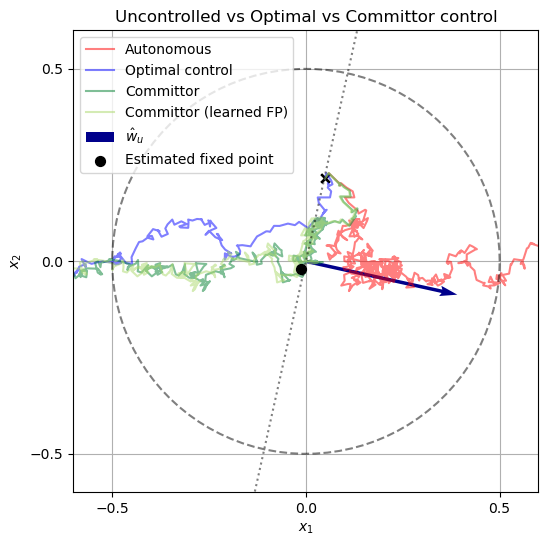

In [156]:
trajectories_info = {
    "Autonomous": (all_X_uncontrolled, "red"),
    "Optimal control": (all_X_opt_ctrld, "blue"),
    #"ReLU control": (all_X_relu_ctrld, "orange"),
    "Committor": (all_X_comm_ctrld, "#007f2f"),
    "Committor (learned FP)": (all_X_comm_ctrld_fp, "#aad96a")
}

fig, ax = plt.subplots(figsize=(6,6))
plot_trajectories(ax, trajectories_info, tracker, show_n=5, title="Uncontrolled vs Optimal vs Committor control")
fig.savefig(f"figures/singletraj_comparison_rs{seed}.pdf", bbox_inches='tight')  
fig.savefig(f"figures/singletraj_comparison_rs{seed}.png", dpi=300, bbox_inches='tight')  
plt.show()


In [ ]:
show_n = 5
plt.figure(figsize=(6,6))

# uncontrolled
for X in all_X_uncontrolled[:show_n]:
    plt.plot(X[:,0], X[:,1], 'r', alpha=0.5, label="Autonomous" if "Autonomous" not in plt.gca().get_legend_handles_labels()[1] else "")
    plt.plot(X[0,0], X[0,1], 'rx')

# Optimal
for X in all_X_opt_ctrld[:show_n]:
    plt.plot(X[:,0], X[:,1], 'b', alpha=0.5, label="Optimal control" if "Optimal control" not in plt.gca().get_legend_handles_labels()[1] else "")
    plt.plot(X[0,0], X[0,1], 'bx')

# ReLU
# for X in all_X_relu_ctrld[:show_n]:
#     plt.plot(X[:,0], X[:,1], 'b', alpha=0.5, label="ReLU control" if "ReLU control" not in plt.gca().get_legend_handles_labels()[1] else "")
#     plt.plot(X[0,0], X[0,1], 'bx')

# Committor
for X in all_X_comm_ctrld[:show_n]:
    plt.plot(X[:,0], X[:,1], 'g', alpha=0.5, label="Committor control" if "Committor control" not in plt.gca().get_legend_handles_labels()[1] else "")
    plt.plot(X[0,0], X[0,1], 'gx')

for X in all_X_comm_ctrld_fp[:show_n]:
    plt.plot(X[:,0], X[:,1], 'k', alpha=0.5, label="Committor control (FP)" if "Committor control (FP)" not in plt.gca().get_legend_handles_labels()[1] else "")
    plt.plot(X[0,0], X[0,1], 'kx')

# reference objects
plt.quiver(0, 0, tracker.l_unstable[0], tracker.l_unstable[1], color='darkblue', scale=3, label="$\hat{w}_u$")
plt.scatter(tracker.b_history[-1,0], tracker.b_history[-1,1], color='k', s=100, zorder=100, label="Estimated fixed point")

thetas = np.linspace(0, 2*np.pi, 100)
plt.plot(0.5*np.cos(thetas), 0.5*np.sin(thetas), 'k--', alpha=0.5)  # neighborhood radius
#plt.plot(0.5*np.cos(thetas) + tracker.b_history[-1,0], 0.5*np.sin(thetas) + tracker.b_history[-1,1], 'k--', alpha=0.5)  # neighborhood radius
relu_line = [[-tracker.l_unstable[1], tracker.l_unstable[1]], [tracker.l_unstable[0], -tracker.l_unstable[0]]]
plt.plot(relu_line[0], relu_line[1], 'k:', alpha=0.5, label="")

plt.xlim([-0.6, 0.6])
plt.ylim([-0.6, 0.6])
plt.xticks([-0.5, 0, 0.5])
plt.yticks([-0.5, 0, 0.5])
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Uncontrolled vs Optimal vs Committor control")
plt.legend()
plt.grid(True)
plt.savefig(f"figures/det_singletraj_comparison_rs{rs}.pdf")
plt.show()

NameError: name 'unstable_mode_control' is not defined

# Empirical committor 

In [ ]:
# Define sets A and B (adjust if needed)
def in_A(x):
    return np.linalg.norm(x - np.array([-0.5, 0.0])) < 0.2

def in_B(x):
    return np.linalg.norm(x - np.array([0.5, 0.0])) < 0.2

# Compute empirical committor on grid
def empirical_committor(sim_func, n_traj=200, T=2000, dt=0.01,
                        min_x=-0.5, max_x=0.5, num_points=10,
                        desc=""):
    grid = np.linspace(min_x, max_x, num_points)
    committor = np.zeros((len(grid), len(grid)))
    print("Calculating the empirical committor for {}".format(desc))
    for i, x1 in enumerate(tqdm(grid, desc="x1 grid")):
        for j, x2 in enumerate(grid):
            x0 = np.array([x1, x2])
            successes = 0
            for k in range(n_traj):
                X = sim_func(x0, T, dt)
                # check hitting A or B first
                for t in range(T):
                    if in_A(X[t]):
                        break
                    if in_B(X[t]):
                        successes += 1
                        break
            committor[j, i] = successes / n_traj
    return grid, committor

# Example simulation wrappers

def simulate_uncontrolled(x0, T, dt):
    X = np.zeros((T, dim))
    X[0] = x0
    noise = np.random.randn(T, dim) * noise_std * np.sqrt(dt)
    for t in range(1, T):
        dx = drift_func(t, X[t-1])
        X[t] = X[t-1] + dx*dt + noise[t]
    return X


def simulate_relu(x0, T, dt):
    X = np.zeros((T, dim))
    X[0] = x0
    noise = np.random.randn(T, dim) * noise_std * np.sqrt(dt)
    for t in range(1, T):
        dx = drift_func(t, X[t-1])
        u_t = relu_control(tracker, X[t-1], r=0.5)
        X[t] = X[t-1] + dx*dt + u_t*dt + noise[t]
    return X


def simulate_committor(x0, T, dt):
    X = np.zeros((T, dim))
    X[0] = x0
    noise = np.random.randn(T, dim) * noise_std * np.sqrt(dt)
    for t in range(1, T):
        dx = drift_func(t, X[t-1])
        u_val = - np.dot(tracker.l_unstable, X[t-1])
        u_t = - high_precision_control([u_val], a=0.5, r=r, D=D, precision=25)[0] * tracker.l_unstable
        X[t] = X[t-1] + dx*dt + u_t*dt + noise[t]
    return X

# Compute empirical committors with progress bar
grid, q_uncontrolled = empirical_committor(simulate_uncontrolled, n_traj=100, desc="Uncontrolled")
_, q_relu = empirical_committor(simulate_relu, n_traj=100, desc="ReLU control")
_, q_comm = empirical_committor(simulate_committor, n_traj=5, desc="Committor control")

Calculating the empirical committor for Uncontrolled


x1 grid: 100%|██████████| 10/10 [01:50<00:00, 11.05s/it]


Calculating the empirical committor for ReLU control


x1 grid: 100%|██████████| 10/10 [07:59<00:00, 47.94s/it]


Calculating the empirical committor for Committor control


x1 grid:  10%|█         | 1/10 [37:28<5:37:17, 2248.61s/it]


KeyboardInterrupt: 

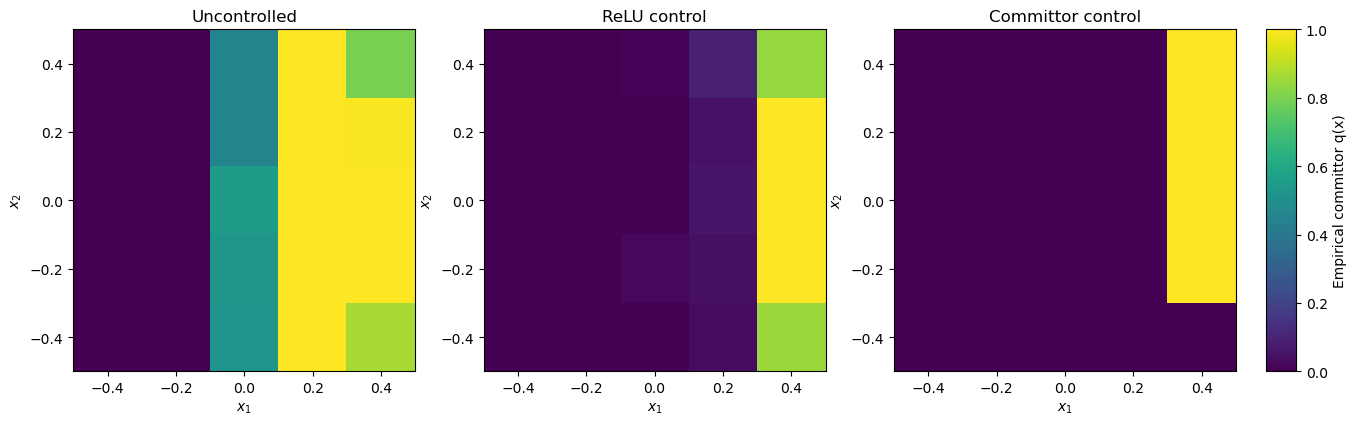

In [262]:
import matplotlib.pyplot as plt

# Plot results
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, q, title in zip(
    axs,
    [q_uncontrolled, q_relu, q_comm],
    ["Uncontrolled", "ReLU control", "Committor control"]
):
    im = ax.imshow(q, origin='lower', extent=[-0.5, 0.5, -0.5, 0.5],
                   vmin=0, vmax=1, cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")

# Get the bounding box of the subplots (they all have same y)
pos = axs[0].get_position()

# Place colorbar all the way to the right, matching subplot height
cbar_ax = fig.add_axes([0.92, pos.y0, 0.02, pos.height])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='vertical')
cbar.set_label("Empirical committor q(x)")

plt.show()
